In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("../data/processed/cleaned_housing.csv")          

In [3]:
df.shape

(20640, 10)

In [4]:
df.columns.to_list()

['longitude',
 'latitude',
 'housing_median_age',
 'total_rooms',
 'total_bedrooms',
 'population',
 'households',
 'median_income',
 'median_house_value',
 'ocean_proximity']

In [5]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,536.838857,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,419.391878,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,297.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,643.250000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [6]:
target = df["median_house_value"]
print(target.mean())
print(target.median())
print(target.std())
print(target.min())
print(target.max())

206855.81690891474
179700.0
115395.61587441387
14999.0
500001.0


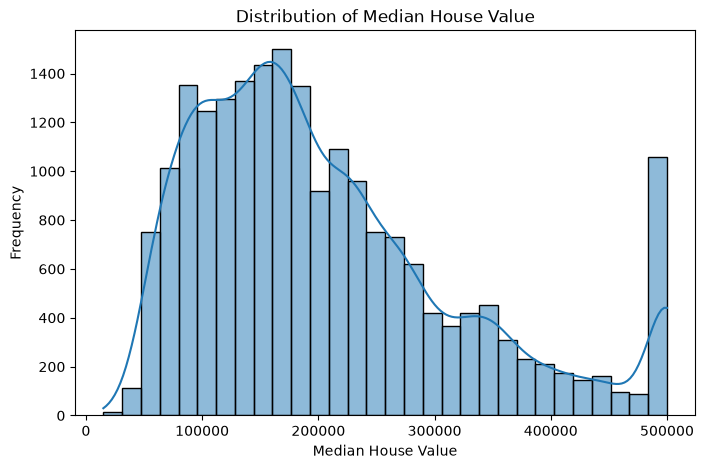

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(df["median_house_value"], bins=30, kde=True)
plt.title("Distribution of Median House Value")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")
plt.show()

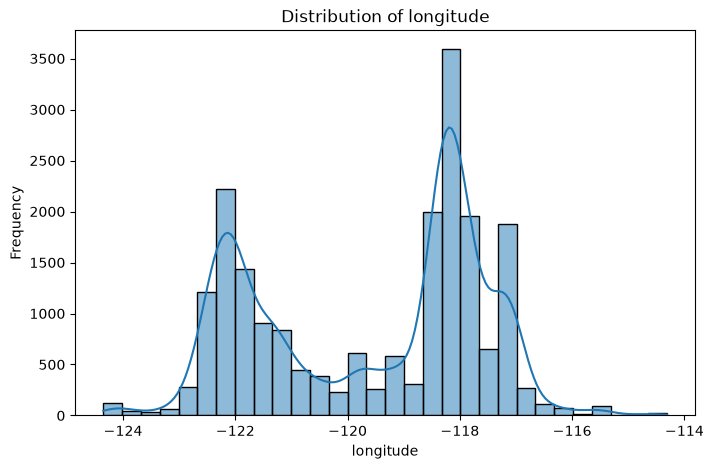

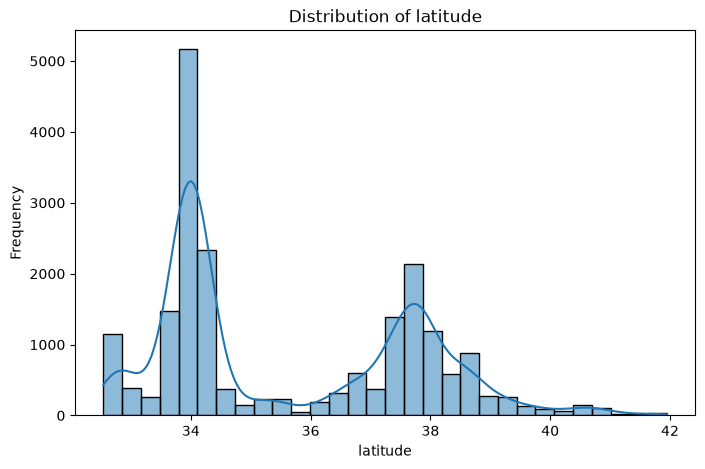

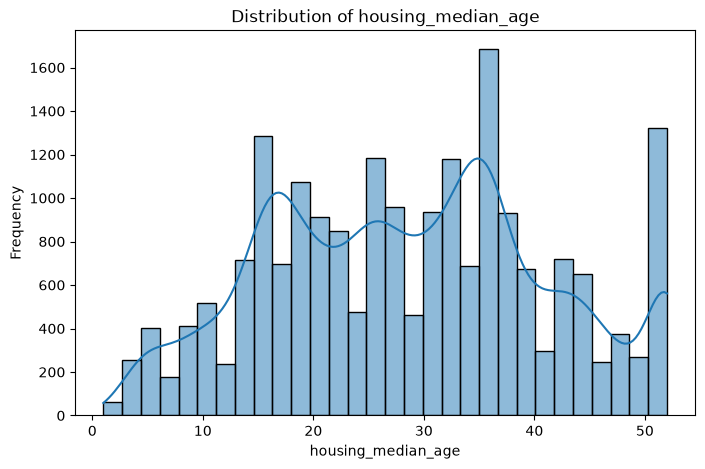

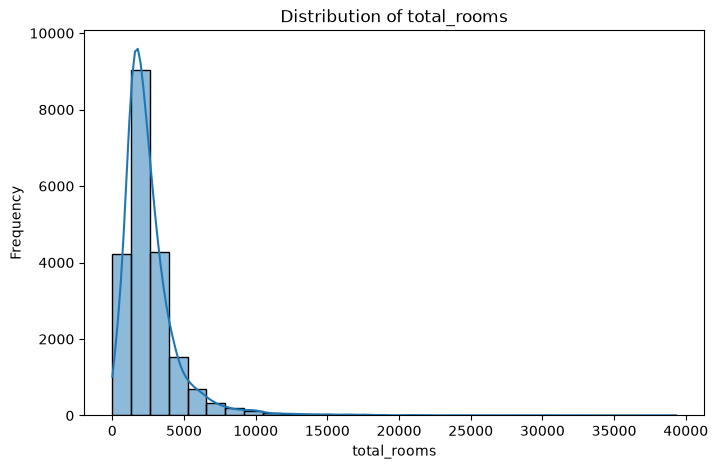

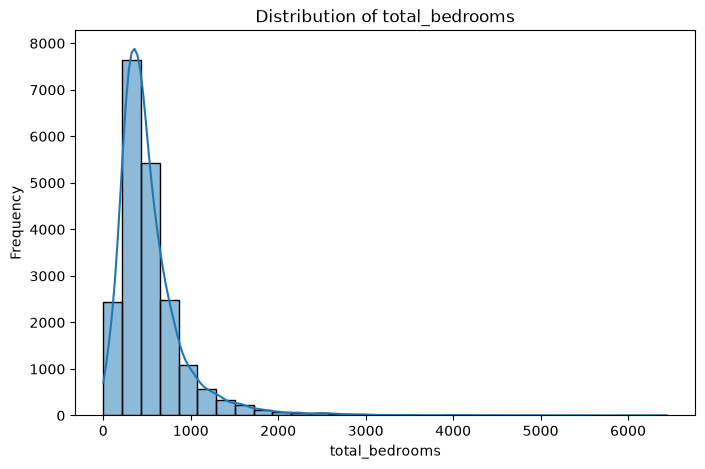

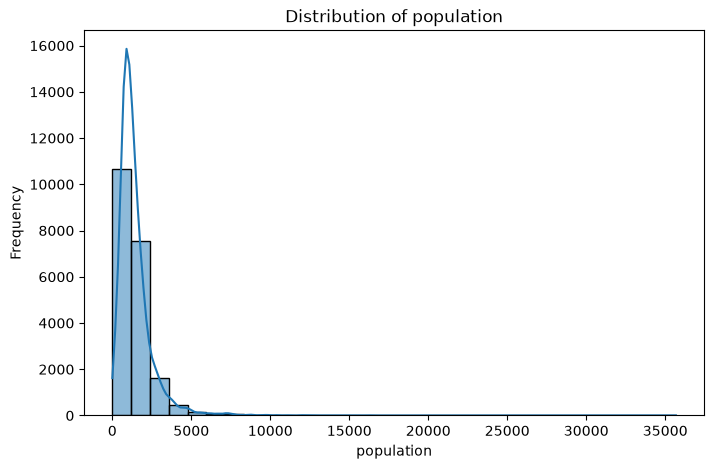

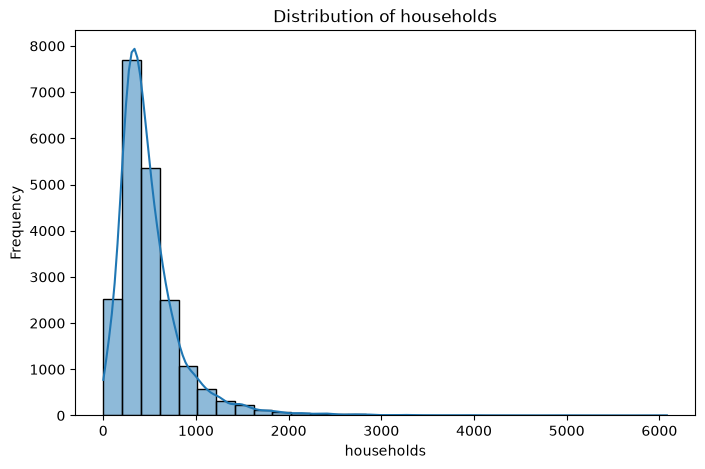

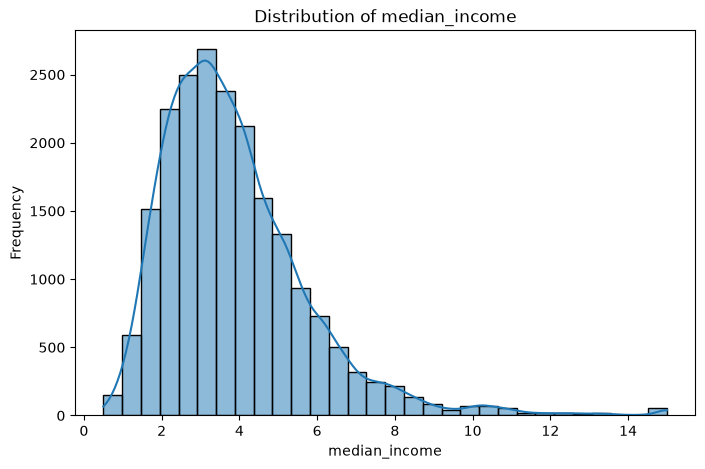

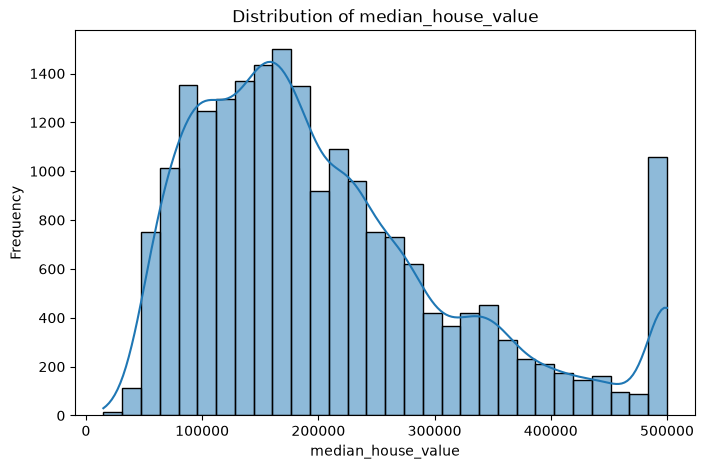

In [9]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns
for column in numeric_columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(df[column], bins=30, kde=True) 
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()

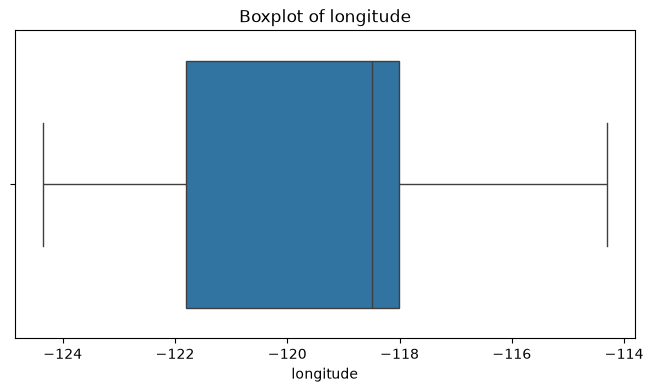

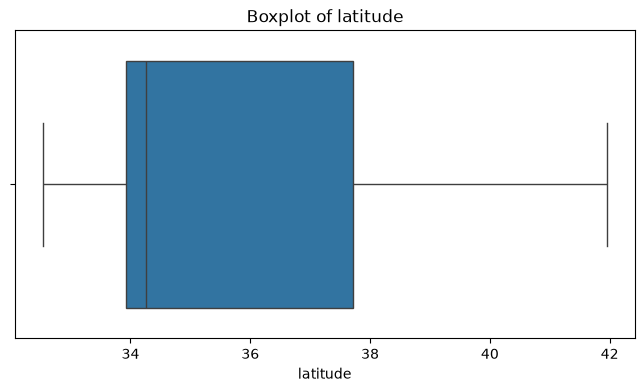

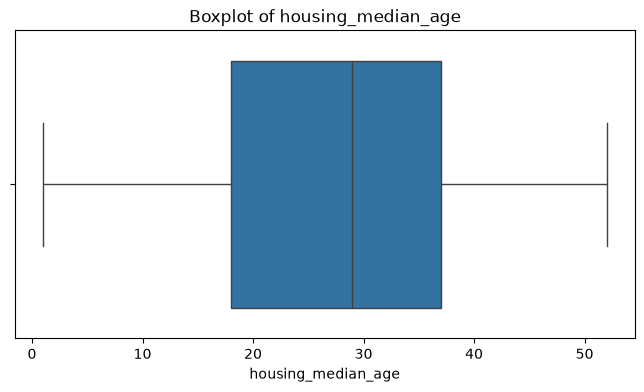

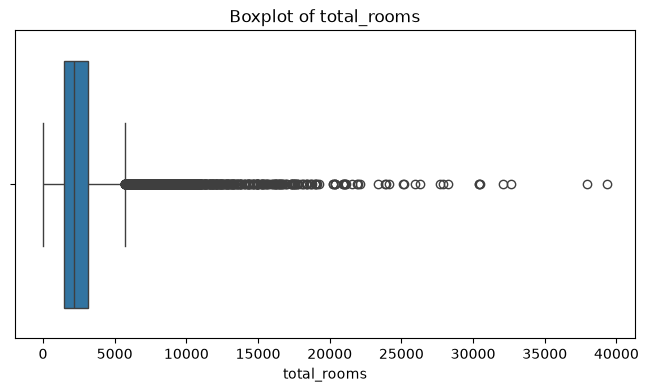

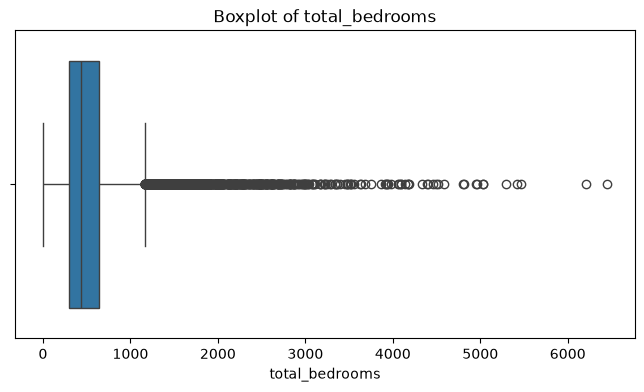

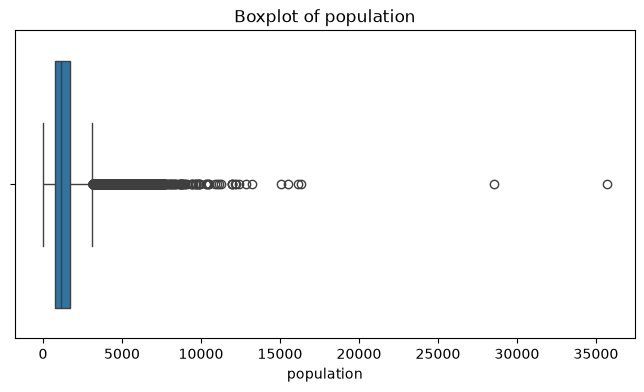

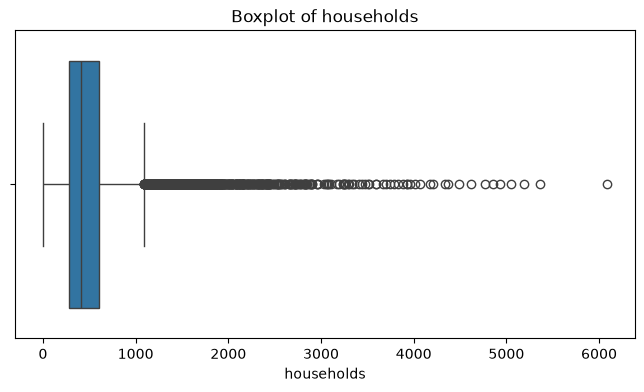

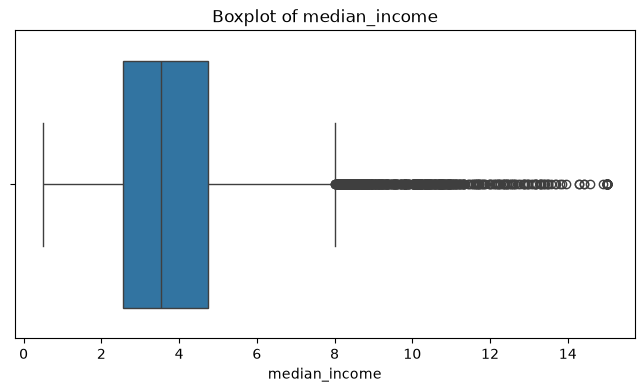

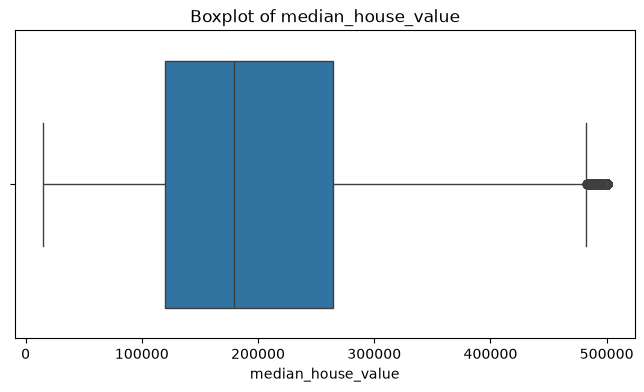

In [10]:
for column in numeric_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(
        x=df[column]
    )
    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    plt.show()

In [11]:
correlation = df.corr(
    numeric_only=True
)
print(correlation)

                    longitude  latitude  housing_median_age  total_rooms  \
longitude            1.000000 -0.924664           -0.108197     0.044568   
latitude            -0.924664  1.000000            0.011173    -0.036100   
housing_median_age  -0.108197  0.011173            1.000000    -0.361262   
total_rooms          0.044568 -0.036100           -0.361262     1.000000   
total_bedrooms       0.069120 -0.066484           -0.319026     0.927058   
population           0.099773 -0.108785           -0.296244     0.857126   
households           0.055310 -0.071035           -0.302916     0.918484   
median_income       -0.015176 -0.079809           -0.119034     0.198050   
median_house_value  -0.045967 -0.144160            0.105623     0.134153   

                    total_bedrooms  population  households  median_income  \
longitude                 0.069120    0.099773    0.055310      -0.015176   
latitude                 -0.066484   -0.108785   -0.071035      -0.079809   
housing_

In [12]:
target_correlation = correlation[
    "median_house_value"
].sort_values(ascending=False)
print(target_correlation)

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049457
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


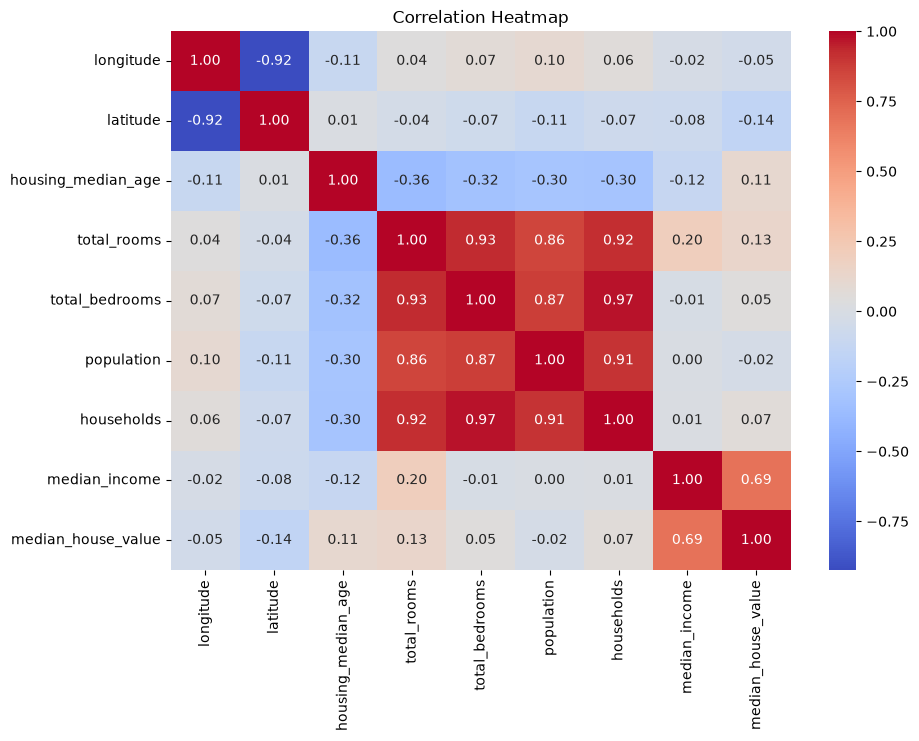

In [13]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

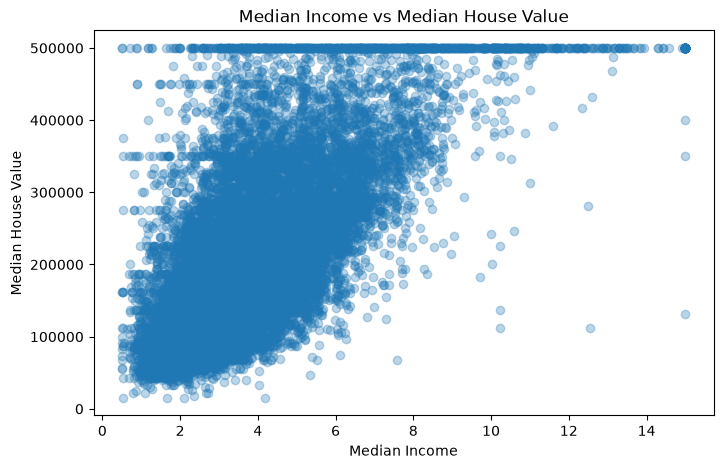

In [15]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df["median_income"],
    df["median_house_value"],
    alpha=0.3
)
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Median Income vs Median House Value")
plt.show()

Text(0.5, 1.0, 'Distribution of Median Income')

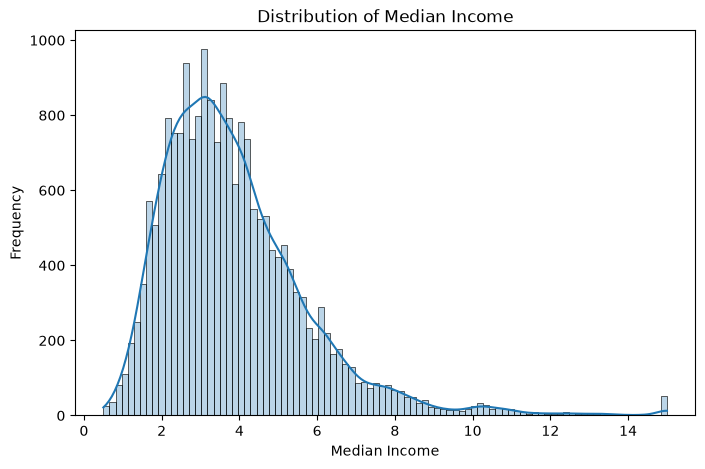

In [17]:
plt.figure(figsize=(8, 5))
sns.histplot(
    df["median_income"],    
    alpha=0.3,
    kde=True
)
plt.xlabel("Median Income")
plt.ylabel("Frequency")
plt.title("Distribution of Median Income")

In [18]:
print(df["ocean_proximity"].value_counts())

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


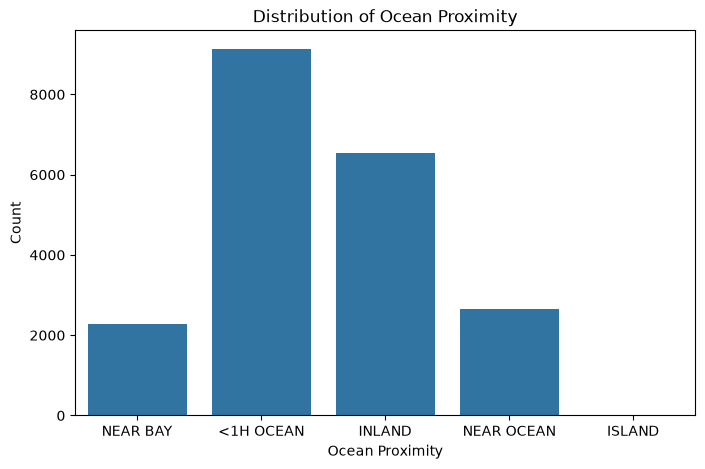

In [20]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="ocean_proximity"
)
plt.title("Distribution of Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Count")
plt.show()

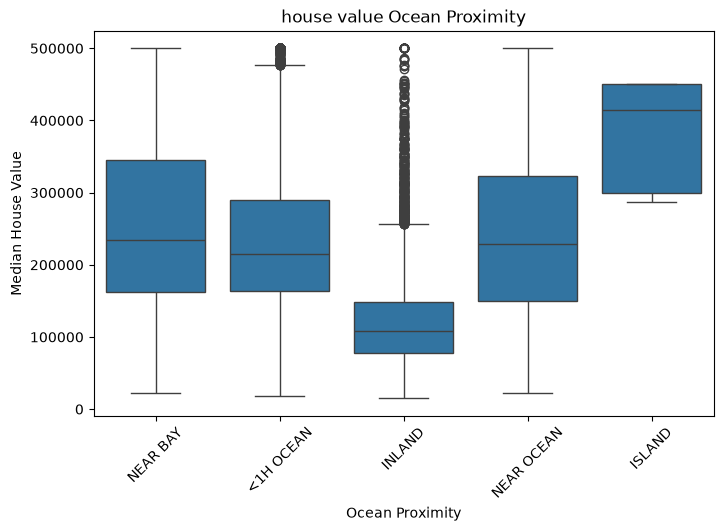

In [21]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="ocean_proximity",
    y="median_house_value"
)
plt.title("house value Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Median House Value")
plt.xticks(rotation=45)
plt.show()

In [22]:
for column in df.select_dtypes(
    include=np.number
).columns:
    print(column,
          "->Min",
          df[column].min(),
          "| Max:", 
          df[column].max())

longitude ->Min -124.35 | Max: -114.31
latitude ->Min 32.54 | Max: 41.95
housing_median_age ->Min 1.0 | Max: 52.0
total_rooms ->Min 2.0 | Max: 39320.0
total_bedrooms ->Min 1.0 | Max: 6445.0
population ->Min 3.0 | Max: 35682.0
households ->Min 1.0 | Max: 6082.0
median_income ->Min 0.4999 | Max: 15.0001
median_house_value ->Min 14999.0 | Max: 500001.0


In [25]:
print("EDA SUMMARY")
print("-" * 30)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print(
    "Numerical Columns:", 
    len(
        df.select_dtypes(
            include=np.number
        ).columns
    )
)
print(
    "Categorical Columns", 
    len(
        df.select_dtypes(
            include="object"
        ).columns
    )
)
print("Target Mean:",      
      df["median_house_value"].mean()
)

print("Target Median:",
      df["median_house_value"].median())

EDA SUMMARY
------------------------------
Rows: 20640
Columns: 10
Numerical Columns: 9
Categorical Columns 1
Target Mean: 206855.81690891474
Target Median: 179700.0


C:\Users\Hp\AppData\Local\Temp\ipykernel_3028\1869087807.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(
